In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp

pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

In [2]:
DATA = Path("../data/processed/south_africa_svir_inputs.csv")
df = pd.read_csv(DATA, parse_dates=["date"])
df = df.sort_values("date").reset_index(drop=True)

print(f"Rows: {len(df)}")
print(f"Date range: {df['date'].min().date()} → {df['date'].max().date()}")
print(f"N: {df['N'].iloc[0]:,.0f}")
df[["date", "S", "V", "I", "Ic", "R", "y_daily_confirmed", "omega_proxy"]].head()

Rows: 525
Date range: 2021-02-16 → 2022-07-25
N: 59,893,884


,date,S,V,I,Ic,R,y_daily_confirmed,omega_proxy
0,2021-02-16,58397345.0,0.0,2420.0,1210.0,1444596.0,1210.0,0.000028
1,2021-02-17,58390385.0,0.0,7060.0,3530.0,1444431.0,2320.0,0.000036
2,2021-02-18,58381144.0,2260.0,11714.0,5857.0,1444201.0,2327.0,0.000044
3,2021-02-19,58371147.0,6524.0,15536.0,7768.0,1444050.0,1911.0,0.000056
4,2021-02-20,58362187.0,10414.0,18916.0,9458.0,1443969.0,1690.0,0.000079


In [3]:
N = float(df["N"].iloc[0])
mu = 9.5 / 1000 / 365
pi = mu * N

params = {
    "pi": pi,
    "mu": mu,
    "omega": 0.001,          # constant fallback
    "sigma": 1/180,
    "epsilon": 0.65,
    "gamma": 1/5,
    "rho1": 1/10,
    "rho2": 1/12,
    "delta": 0.001,
    "beta": 0.25,
}

# Initial conditions from the first row
y0 = [
    df["S"].iloc[0],
    df["V"].iloc[0],
    df["I"].iloc[0],
    df["Ic"].iloc[0],
    df["R"].iloc[0],
]
print("y0 (S, V, I, Ic, R):")
print([f"{v:,.1f}" for v in y0])
print("\nParameters:")
for k, v in params.items():
    print(f"  {k:8s} = {v:.6g}")

y0 (S, V, I, Ic, R):
['58,397,345.0', '0.0', '2,420.0', '1,210.0', '1,444,596.0']

Parameters:
  pi       = 1558.88
  mu       = 2.60274e-05
  omega    = 0.001
  sigma    = 0.00555556
  epsilon  = 0.65
  gamma    = 0.2
  rho1     = 0.1
  rho2     = 0.0833333
  delta    = 0.001
  beta     = 0.25


In [4]:
def svir_ode(t, y, p, omega_func=None):
    """SVIR right-hand side.
    y = [S, V, I, Ic, R]
    If omega_func is given it is called as omega_func(t).
    """
    S, V, I, Ic, R = y
    N = p.get("N", S + V + I + Ic + R)

    beta    = p["beta"]
    epsilon = p["epsilon"]
    gamma   = p["gamma"]
    rho1    = p["rho1"]
    rho2    = p["rho2"]
    delta   = p["delta"]
    sigma   = p["sigma"]
    mu      = p["mu"]
    pi      = p["pi"]

    omega = omega_func(t) if omega_func is not None else p["omega"]

    lam = beta * (I + Ic) / N

    dS  = pi + sigma * V - lam * S - omega * S - mu * S
    dV  = omega * S - (1 - epsilon) * lam * V - sigma * V - mu * V
    dI  = lam * S + (1 - epsilon) * lam * V - (mu + gamma + rho1 + delta) * I
    dIc = gamma * I - (mu + rho2 + delta) * Ic
    dR  = rho1 * I + rho2 * Ic - mu * R

    return [dS, dV, dI, dIc, dR]

In [5]:
t_eval = np.arange(len(df))
t_span = (t_eval[0], t_eval[-1])

params["N"] = N

sol = solve_ivp(
    fun=lambda t, y: svir_ode(t, y, params),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
)

print("Success:", sol.success)
print("Message:", sol.message)

Success: True
Message: The solver successfully reached the end of the integration interval.


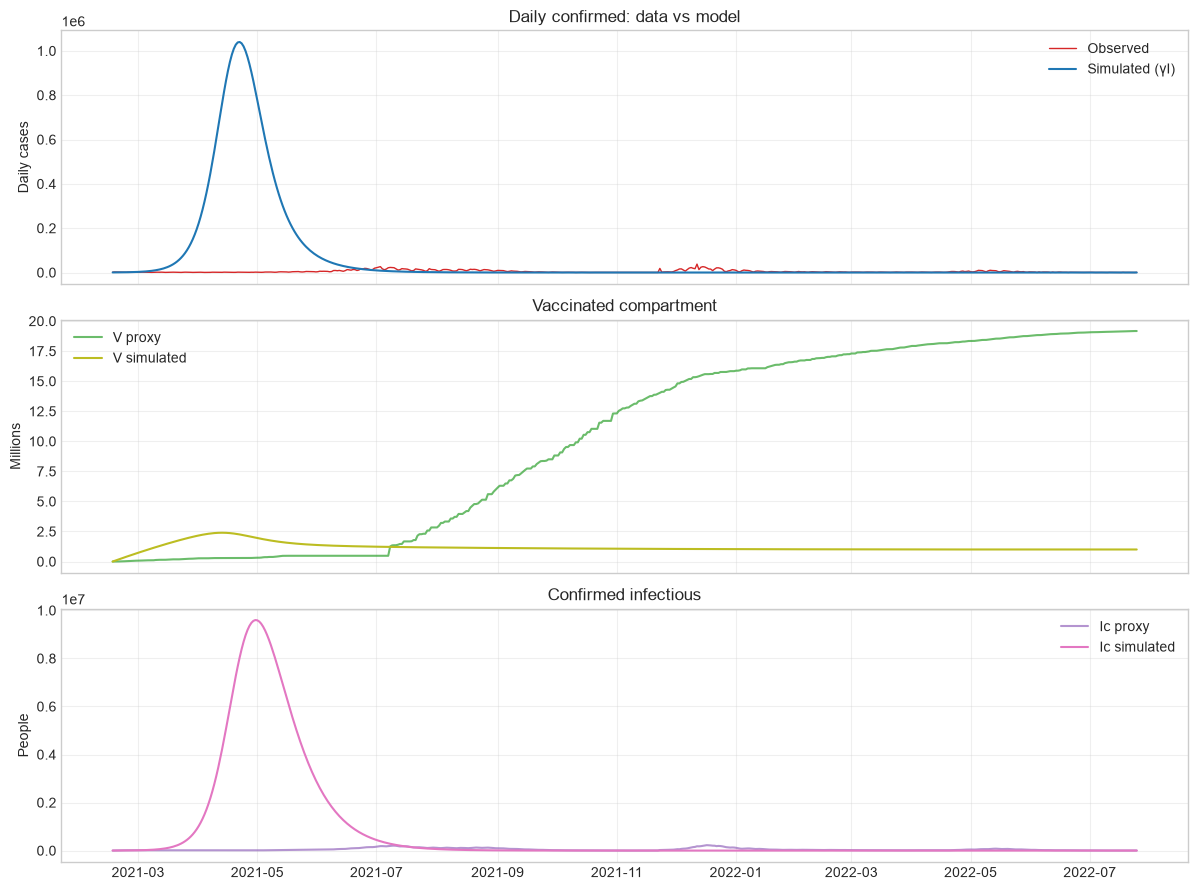

In [6]:
sim = pd.DataFrame({
    "date": df["date"],
    "S_sim": sol.y[0],
    "V_sim": sol.y[1],
    "I_sim": sol.y[2],
    "Ic_sim": sol.y[3],
    "R_sim": sol.y[4],
})

# Model-implied daily new confirmed ≈ γ · I
sim["daily_confirmed_sim"] = params["gamma"] * sim["I_sim"]

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df["date"], df["y_daily_confirmed"], label="Observed", color="tab:red", lw=1)
axes[0].plot(sim["date"], sim["daily_confirmed_sim"], label="Simulated (γI)", color="tab:blue", lw=1.5)
axes[0].set_ylabel("Daily cases")
axes[0].legend()
axes[0].set_title("Daily confirmed: data vs model")

axes[1].plot(df["date"], df["V"] / 1e6, label="V proxy", color="tab:green", alpha=0.7)
axes[1].plot(sim["date"], sim["V_sim"] / 1e6, label="V simulated", color="tab:olive", lw=1.5)
axes[1].set_ylabel("Millions")
axes[1].legend()
axes[1].set_title("Vaccinated compartment")

axes[2].plot(df["date"], df["Ic"], label="Ic proxy", color="tab:purple", alpha=0.7)
axes[2].plot(sim["date"], sim["Ic_sim"], label="Ic simulated", color="tab:pink", lw=1.5)
axes[2].set_ylabel("People")
axes[2].legend()
axes[2].set_title("Confirmed infectious")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Success: True


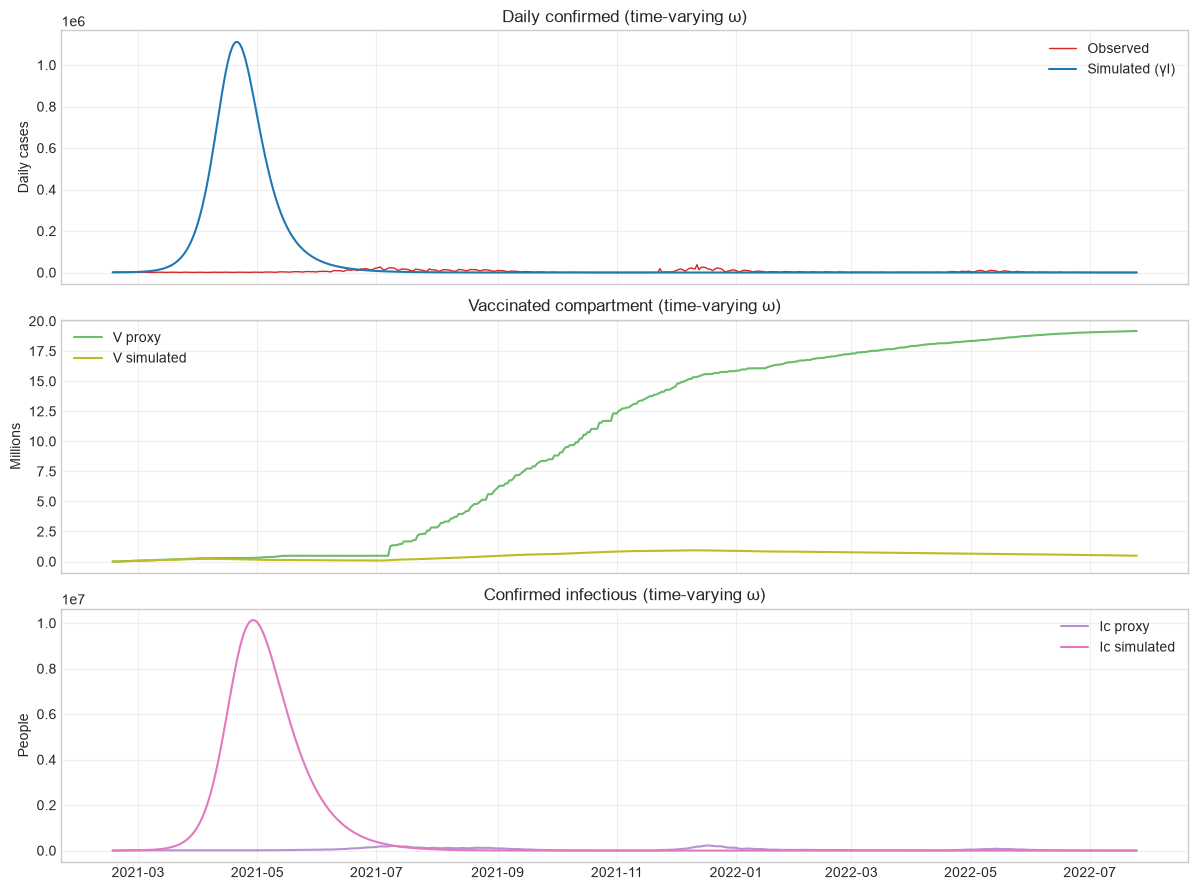

In [7]:
# Interpolator for the observed vaccination rate
from scipy.interpolate import interp1d

omega_interp = interp1d(
    np.arange(len(df)),
    df["omega_proxy"].values,
    bounds_error=False,
    fill_value=(df["omega_proxy"].iloc[0], df["omega_proxy"].iloc[-1])
)

def omega_func(t):
    return float(omega_interp(t))

# Re-integrate with time-varying ω
sol_tv = solve_ivp(
    fun=lambda t, y: svir_ode(t, y, params, omega_func=omega_func),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
)

print("Success:", sol_tv.success)

# Rebuild comparison frame
sim_tv = pd.DataFrame({
    "date": df["date"],
    "S_sim": sol_tv.y[0],
    "V_sim": sol_tv.y[1],
    "I_sim": sol_tv.y[2],
    "Ic_sim": sol_tv.y[3],
    "R_sim": sol_tv.y[4],
})
sim_tv["daily_confirmed_sim"] = params["gamma"] * sim_tv["I_sim"]

# Plot again
fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)

axes[0].plot(df["date"], df["y_daily_confirmed"], label="Observed", color="tab:red", lw=1)
axes[0].plot(sim_tv["date"], sim_tv["daily_confirmed_sim"], label="Simulated (γI)", color="tab:blue", lw=1.5)
axes[0].set_ylabel("Daily cases")
axes[0].legend()
axes[0].set_title("Daily confirmed (time-varying ω)")

axes[1].plot(df["date"], df["V"] / 1e6, label="V proxy", color="tab:green", alpha=0.7)
axes[1].plot(sim_tv["date"], sim_tv["V_sim"] / 1e6, label="V simulated", color="tab:olive", lw=1.5)
axes[1].set_ylabel("Millions")
axes[1].legend()
axes[1].set_title("Vaccinated compartment (time-varying ω)")

axes[2].plot(df["date"], df["Ic"], label="Ic proxy", color="tab:purple", alpha=0.7)
axes[2].plot(sim_tv["date"], sim_tv["Ic_sim"], label="Ic simulated", color="tab:pink", lw=1.5)
axes[2].set_ylabel("People")
axes[2].legend()
axes[2].set_title("Confirmed infectious (time-varying ω)")

for ax in axes:
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Best β = 0.1059
MSE    = 41,417,598.6


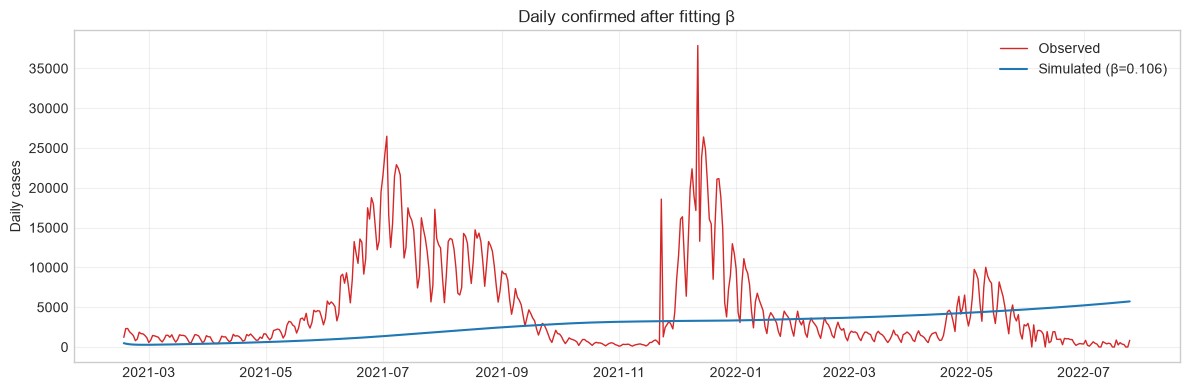

In [8]:
from scipy.optimize import minimize_scalar

def simulate_beta(beta):
    p = params.copy()
    p["beta"] = beta
    p["N"] = N
    sol = solve_ivp(
        fun=lambda t, y: svir_ode(t, y, p, omega_func=omega_func),
        t_span=t_span,
        y0=y0,
        t_eval=t_eval,
        method="RK45",
        rtol=1e-5,
        atol=1e-7,
    )
    if not sol.success:
        return np.inf
    daily_sim = p["gamma"] * sol.y[2]          # γ · I
    # Mean squared error on daily confirmed
    mse = np.mean((daily_sim - df["y_daily_confirmed"].values)**2)
    return mse

# Search over a reasonable range
res = minimize_scalar(simulate_beta, bounds=(0.01, 0.5), method="bounded", options={"xatol": 1e-4})
print(f"Best β = {res.x:.4f}")
print(f"MSE    = {res.fun:,.1f}")

# Re-simulate with the fitted β
params_fit = params.copy()
params_fit["beta"] = res.x
params_fit["N"] = N

sol_fit = solve_ivp(
    fun=lambda t, y: svir_ode(t, y, params_fit, omega_func=omega_func),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
)

sim_fit = pd.DataFrame({
    "date": df["date"],
    "I_sim": sol_fit.y[2],
    "Ic_sim": sol_fit.y[3],
    "V_sim": sol_fit.y[1],
})
sim_fit["daily_confirmed_sim"] = params_fit["gamma"] * sim_fit["I_sim"]

# Plot
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["y_daily_confirmed"], label="Observed", color="tab:red", lw=1)
ax.plot(sim_fit["date"], sim_fit["daily_confirmed_sim"], label=f"Simulated (β={res.x:.3f})", color="tab:blue", lw=1.5)
ax.set_ylabel("Daily cases")
ax.legend()
ax.set_title("Daily confirmed after fitting β")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

2021-02-16 → 2021-06-30: β = 0.125
2021-07-01 → 2021-11-30: β = 0.218
2021-12-01 → 2022-07-25: β = 0.105


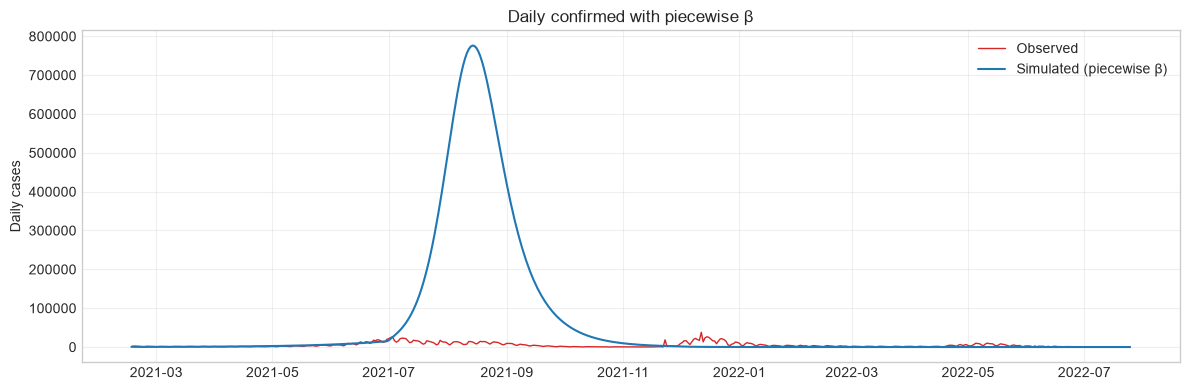

In [9]:
# Define periods roughly matching the main waves in your data
periods = [
    ("2021-02-16", "2021-06-30"),   # early / pre-Delta
    ("2021-07-01", "2021-11-30"),   # Delta
    ("2021-12-01", "2022-07-25"),   # Omicron and after
]

beta_tv = np.zeros(len(df))

for start, end in periods:
    mask = (df["date"] >= start) & (df["date"] <= end)
    if mask.sum() < 10:
        continue

    def mse_period(beta):
        p = params.copy()
        p["beta"] = beta
        p["N"] = N
        # Integrate only over the whole interval but evaluate MSE only on the window
        sol = solve_ivp(
            fun=lambda t, y: svir_ode(t, y, p, omega_func=omega_func),
            t_span=t_span,
            y0=y0,
            t_eval=t_eval,
            method="RK45",
            rtol=1e-5,
            atol=1e-7,
        )
        if not sol.success:
            return np.inf
        daily_sim = p["gamma"] * sol.y[2]
        return np.mean((daily_sim[mask] - df.loc[mask, "y_daily_confirmed"].values)**2)

    res_p = minimize_scalar(mse_period, bounds=(0.01, 0.4), method="bounded", options={"xatol": 1e-3})
    beta_tv[mask] = res_p.x
    print(f"{start} → {end}: β = {res_p.x:.3f}")

# Simulate once with the piecewise β (approximate by interpolating the step function)
beta_interp = interp1d(np.arange(len(df)), beta_tv, bounds_error=False, fill_value="extrapolate")

def beta_func(t):
    return float(beta_interp(t))

# Modified ODE that accepts beta_func
def svir_ode_tv(t, y, p, omega_func, beta_func):
    p = p.copy()
    p["beta"] = beta_func(t)
    return svir_ode(t, y, p, omega_func=omega_func)

sol_pw = solve_ivp(
    fun=lambda t, y: svir_ode_tv(t, y, params, omega_func, beta_func),
    t_span=t_span,
    y0=y0,
    t_eval=t_eval,
    method="RK45",
    rtol=1e-6,
    atol=1e-8,
)

sim_pw = pd.DataFrame({
    "date": df["date"],
    "daily_confirmed_sim": params["gamma"] * sol_pw.y[2],
})

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df["date"], df["y_daily_confirmed"], label="Observed", color="tab:red", lw=1)
ax.plot(sim_pw["date"], sim_pw["daily_confirmed_sim"], label="Simulated (piecewise β)", color="tab:blue", lw=1.5)
ax.set_ylabel("Daily cases")
ax.legend()
ax.set_title("Daily confirmed with piecewise β")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [10]:
# How large is the model-implied daily cases relative to data at the peak?
peak_idx = sim_pw["daily_confirmed_sim"].idxmax()
print("Model peak:", sim_pw["daily_confirmed_sim"].max())
print("Data around that date:", df.loc[peak_idx-5:peak_idx+5, "y_daily_confirmed"].mean())
print("Ratio:", sim_pw["daily_confirmed_sim"].max() / df["y_daily_confirmed"].max())

Model peak: 776157.6651223933
Data around that date: 10835.09090909091
Ratio: 20.492611620393223


In [11]:
# Use the last simulation you have (piecewise or constant-β).
# Replace sim_pw with sim_fit or sim_tv if you prefer that run.
sim = sim_pw.copy()          # or sim_fit / sim_tv
sim["y_obs"] = df["y_daily_confirmed"].values
sim["y_mech"] = sim["daily_confirmed_sim"]          # γ · I
sim["residual"] = sim["y_obs"] - sim["y_mech"]

# Simple features for the residual model
sim["t"] = np.arange(len(sim))
sim["t_norm"] = sim["t"] / sim["t"].max()
sim["vax_coverage"] = df["full_vax_coverage"].values
sim["month"] = sim["date"].dt.month
sim["dow"] = sim["date"].dt.dayofweek

print(sim[["date", "y_obs", "y_mech", "residual"]].describe())
sim[["date", "y_obs", "y_mech", "residual"]].head()

                      date         y_obs         y_mech       residual
count                  525    525.000000     525.000000     525.000000
mean   2021-11-05 00:00:00   4781.089524   62213.504102  -57432.414579
min    2021-02-16 00:00:00      0.000000       0.000057 -764811.959068
25%    2021-06-27 00:00:00    989.000000       0.521157   -4669.339371
50%    2021-11-05 00:00:00   2191.000000     679.320647     462.999802
75%    2022-03-16 00:00:00   6527.000000   11192.678052    2092.998518
max    2022-07-25 00:00:00  37875.000000  776157.665122   37458.422072
std                    NaN   5705.643604  165283.841902  163468.731214


,date,y_obs,y_mech,residual
0,2021-02-16,1210.0,484.000000,726.000000
1,2021-02-17,2320.0,435.374463,1884.625537
2,2021-02-18,2327.0,401.524648,1925.475352
3,2021-02-19,1911.0,378.749811,1532.250189
4,2021-02-20,1690.0,364.296258,1325.703742


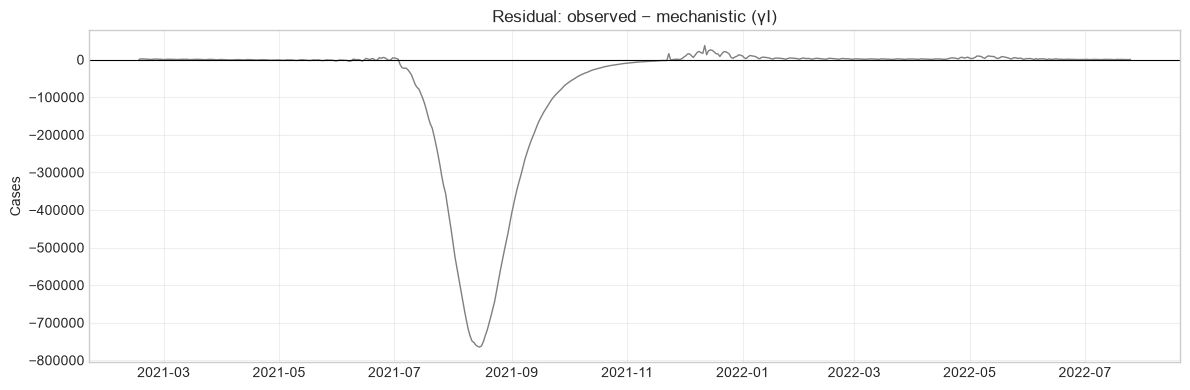

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sim["date"], sim["residual"], color="tab:gray", lw=1)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Residual: observed − mechanistic (γI)")
ax.set_ylabel("Cases")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Use the constant-β simulation (closer scale)
sim = sim_fit.copy()          # the one produced by the minimize_scalar fit
sim["y_obs"] = df["y_daily_confirmed"].values
sim["y_mech"] = sim["daily_confirmed_sim"]
sim["residual"] = sim["y_obs"] - sim["y_mech"]

sim["t"] = np.arange(len(sim))
sim["t_norm"] = sim["t"] / sim["t"].max()
sim["vax_coverage"] = df["full_vax_coverage"].values
sim["month"] = sim["date"].dt.month
sim["dow"] = sim["date"].dt.dayofweek

print(sim[["y_obs", "y_mech", "residual"]].describe())

              y_obs       y_mech      residual
count    525.000000   525.000000    525.000000
mean    4781.089524  2768.229471   2012.860053
std     5705.643604  1533.039031   6118.692124
min        0.000000   280.568204  -5707.205566
25%      989.000000  1295.346598  -2322.643389
50%     2191.000000  3185.211151    456.324665
75%     6527.000000  3810.372168   3889.444750
max    37875.000000  5729.689808  34588.604615


In [17]:
pip install scikit-learn

     ---------------------------------------- 8.3/8.3 MB 3.3 MB/s eta 0:00:00
     -------------------------------------- 306.1/306.1 kB 3.8 MB/s eta 0:00:00
     -------------------------------------- 483.2/483.2 kB 2.7 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip available: 22.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [18]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Features and target
feature_cols = ["t_norm", "vax_coverage", "month", "dow"]
X = sim[feature_cols]
y = sim["residual"]

# Time-series cross-validation (respects order)
tscv = TimeSeriesSplit(n_splits=5)
maes, rmses = [], []

for train_idx, test_idx in tscv.split(X):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    model = HistGradientBoostingRegressor(
        max_iter=200,
        max_depth=4,
        learning_rate=0.05,
        random_state=42
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    maes.append(mean_absolute_error(y_te, pred))
    rmses.append(np.sqrt(mean_squared_error(y_te, pred)))

print(f"CV MAE:  {np.mean(maes):.0f} ± {np.std(maes):.0f}")
print(f"CV RMSE: {np.mean(rmses):.0f} ± {np.std(rmses):.0f}")

# Final model on all data (for illustration / later forecasting)
final_model = HistGradientBoostingRegressor(
    max_iter=200, max_depth=4, learning_rate=0.05, random_state=42
)
final_model.fit(X, y)
sim["residual_hat"] = final_model.predict(X)
sim["y_hybrid"] = sim["y_mech"] + sim["residual_hat"]

CV MAE:  6890 ± 2684
CV RMSE: 8467 ± 3327


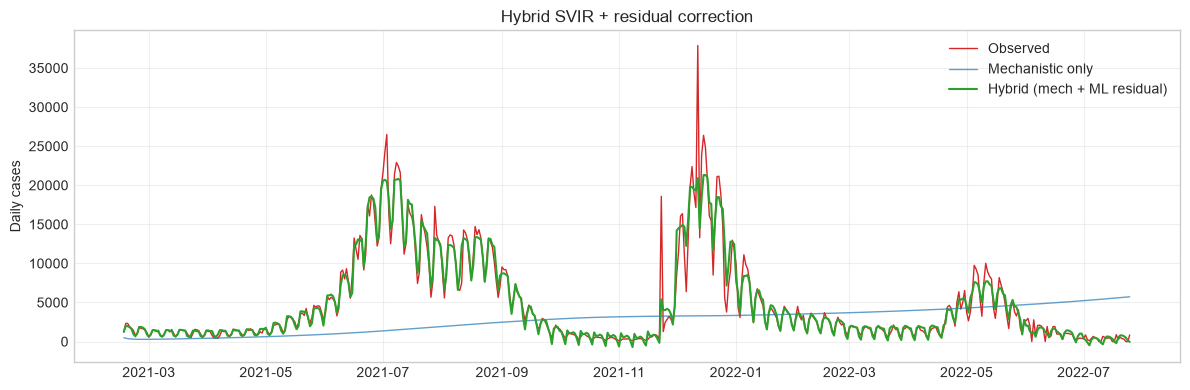

Hybrid MAE: 664
Mech-only MAE: 4263


In [19]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sim["date"], sim["y_obs"], label="Observed", color="tab:red", lw=1)
ax.plot(sim["date"], sim["y_mech"], label="Mechanistic only", color="tab:blue", lw=1, alpha=0.7)
ax.plot(sim["date"], sim["y_hybrid"], label="Hybrid (mech + ML residual)", color="tab:green", lw=1.5)
ax.set_ylabel("Daily cases")
ax.legend()
ax.set_title("Hybrid SVIR + residual correction")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"Hybrid MAE: {mean_absolute_error(sim['y_obs'], sim['y_hybrid']):.0f}")
print(f"Mech-only MAE: {mean_absolute_error(sim['y_obs'], sim['y_mech']):.0f}")

In [20]:
# Add lagged residuals (shift so we never use future information)
for lag in [1, 7, 14]:
    sim[f"resid_lag{lag}"] = sim["residual"].shift(lag)

# Drop the first 14 rows where lags are missing
sim_lag = sim.dropna().reset_index(drop=True)

feature_cols_lag = ["t_norm", "vax_coverage", "month", "dow",
                    "resid_lag1", "resid_lag7", "resid_lag14"]
X = sim_lag[feature_cols_lag]
y = sim_lag["residual"]

tscv = TimeSeriesSplit(n_splits=5)
maes, rmses = [], []

for train_idx, test_idx in tscv.split(X):
    X_tr, X_te = X.iloc[train_idx], X.iloc[test_idx]
    y_tr, y_te = y.iloc[train_idx], y.iloc[test_idx]

    model = HistGradientBoostingRegressor(
        max_iter=150,
        max_depth=3,          # slightly shallower to reduce over-fit
        learning_rate=0.05,
        min_samples_leaf=20,
        random_state=42
    )
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    maes.append(mean_absolute_error(y_te, pred))
    rmses.append(np.sqrt(mean_squared_error(y_te, pred)))

print(f"CV MAE (with lags):  {np.mean(maes):.0f} ± {np.std(maes):.0f}")
print(f"CV RMSE (with lags): {np.mean(rmses):.0f} ± {np.std(rmses):.0f}")

CV MAE (with lags):  3301 ± 2398
CV RMSE (with lags): 4189 ± 2917


In [22]:
HORIZON = 90
STEP = 90
results = []

for start in range(90, len(sim_lag) - HORIZON, STEP):   # start after enough history
    train = sim_lag.iloc[:start]
    test  = sim_lag.iloc[start:start + HORIZON]

    X_tr = train[feature_cols_lag]
    y_tr = train["residual"]
    X_te = test[feature_cols_lag]

    model = HistGradientBoostingRegressor(
        max_iter=150, max_depth=3, learning_rate=0.05,
        min_samples_leaf=20, random_state=42
    )
    model.fit(X_tr, y_tr)
    resid_hat = model.predict(X_te)

    y_mech_te = test["y_mech"].values
    y_hybrid  = y_mech_te + resid_hat
    y_true    = test["y_obs"].values

    mae_hybrid = mean_absolute_error(y_true, y_hybrid)
    mae_mech   = mean_absolute_error(y_true, y_mech_te)

    results.append({
        "train_end": train["date"].iloc[-1],
        "mae_hybrid": mae_hybrid,
        "mae_mech": mae_mech,
    })

res_df = pd.DataFrame(results)
print(res_df)
print(f"\nMean MAE hybrid: {res_df['mae_hybrid'].mean():.0f}")
print(f"Mean MAE mech:   {res_df['mae_mech'].mean():.0f}")

   train_end   mae_hybrid      mae_mech
0 2021-05-30  7563.407653  10537.230159
1 2021-08-28  4485.276110   2634.965547
2 2021-11-26  2721.471592   5340.675794
3 2022-02-24   956.778505   2257.719322

Mean MAE hybrid: 3932
Mean MAE mech:   5193
